<a href="https://colab.research.google.com/github/nouraastafofana-droid/brain-tumor-mri-segmentation/blob/main/notebooks/01_data_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [2]:
!kaggle datasets download \
    -d briscdataset/brisc2025 \
    -p /content/data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/briscdataset/brisc2025
License(s): Attribution 4.0 International (CC BY 4.0)
100% 250M/250M [00:03<00:00, 79.1MB/s]



In [3]:
from pathlib import Path

DATA_ROOT = Path("/content/data")

for path in sorted(DATA_ROOT.rglob("*")):
    if path.is_dir():
        print(path)

/content/data/brisc2025
/content/data/brisc2025/classification_task
/content/data/brisc2025/classification_task/test
/content/data/brisc2025/classification_task/test/glioma
/content/data/brisc2025/classification_task/test/meningioma
/content/data/brisc2025/classification_task/test/no_tumor
/content/data/brisc2025/classification_task/test/pituitary
/content/data/brisc2025/classification_task/train
/content/data/brisc2025/classification_task/train/glioma
/content/data/brisc2025/classification_task/train/meningioma
/content/data/brisc2025/classification_task/train/no_tumor
/content/data/brisc2025/classification_task/train/pituitary
/content/data/brisc2025/segmentation_task
/content/data/brisc2025/segmentation_task/test
/content/data/brisc2025/segmentation_task/test/images
/content/data/brisc2025/segmentation_task/test/masks
/content/data/brisc2025/segmentation_task/train
/content/data/brisc2025/segmentation_task/train/images
/content/data/brisc2025/segmentation_task/train/masks


In [4]:
import pandas as pd

manifest_files = list(DATA_ROOT.rglob("manifest.csv"))
manifest_files

[PosixPath('/content/data/brisc2025/manifest.csv')]

In [5]:
manifest = pd.read_csv(manifest_files[0])

print(manifest.shape)
print(manifest.columns.tolist())

display(manifest.head())

(15586, 16)
['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256']


,relative_path,filename,task,split,index,tumor_code,tumor_label,plane_code,plane_label,sequence,is_mask,linked_image,width,height,file_size_bytes,sha256
0,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg,classification,test,1,gl,glioma,ax,axial,T1,False,NaN,512,512,25826,b513a83f68e486f45159b004d356782e78284014532151...
1,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg,classification,test,2,gl,glioma,ax,axial,T1,False,NaN,512,512,20982,5b4e4a0f482cb68955c340205d475f25c3a30718bd3b48...
2,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg,classification,test,3,gl,glioma,ax,axial,T1,False,NaN,512,512,13285,6fd1918b39e7a7f92fa5652d7802583f3251fed50a23ec...
3,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00004_gl_ax_t1.jpg,classification,test,4,gl,glioma,ax,axial,T1,False,NaN,512,512,26137,216b65a45d7effb4ebce1c9893f97d12449c9da777f818...
4,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00005_gl_ax_t1.jpg,classification,test,5,gl,glioma,ax,axial,T1,False,NaN,512,512,21709,c35734545021ab5a4f55fb87e08732e26fb16abe887927...


In [6]:
# Manifest structure
print("Total manifest rows:", len(manifest))

print("\nRows by task:")
display(
    manifest.groupby(["task", "is_mask"])
            .size()
            .rename("n")
            .reset_index()
)

print("\nRows by task / split / mask status:")
display(
    manifest.groupby(["task", "split", "is_mask"])
            .size()
            .rename("n")
            .reset_index()
)

print("\nTumor labels:")
display(
    manifest.groupby(["task", "tumor_label", "is_mask"])
            .size()
            .rename("n")
            .reset_index()
)

Total manifest rows: 15586

Rows by task:


,task,is_mask,n
0,classification,False,6000
1,segmentation,False,4793
2,segmentation,True,4793



Rows by task / split / mask status:


,task,split,is_mask,n
0,classification,test,False,1000
1,classification,train,False,5000
2,segmentation,test,False,860
3,segmentation,test,True,860
4,segmentation,train,False,3933
5,segmentation,train,True,3933



Tumor labels:


,task,tumor_label,is_mask,n
0,classification,glioma,False,1401
1,classification,meningioma,False,1635
2,classification,no_tumor,False,1207
3,classification,pituitary,False,1757
4,segmentation,glioma,False,1401
5,segmentation,glioma,True,1401
6,segmentation,meningioma,False,1635
7,segmentation,meningioma,True,1635
8,segmentation,pituitary,False,1757
9,segmentation,pituitary,True,1757


In [7]:
seg = manifest[manifest["task"] == "segmentation"].copy()

print("Segmentation manifest rows:", len(seg))

seg_images = seg[~seg["is_mask"]].copy()
seg_masks  = seg[seg["is_mask"]].copy()

print("Segmentation images:", len(seg_images))
print("Segmentation masks :", len(seg_masks))

Segmentation manifest rows: 9586
Segmentation images: 4793
Segmentation masks : 4793


In [8]:
print("Masks without linked_image:",
      seg_masks["linked_image"].isna().sum())

print("Unique linked images:",
      seg_masks["linked_image"].nunique())

print("Unique image filenames:",
      seg_images["filename"].nunique())

display(
    seg_masks[
        ["filename", "linked_image", "tumor_label",
         "plane_label", "split"]
    ].head(10)
)

Masks without linked_image: 0
Unique linked images: 4793
Unique image filenames: 4793


,filename,linked_image,tumor_label,plane_label,split
6860,brisc2025_test_00001_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6861,brisc2025_test_00002_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6862,brisc2025_test_00003_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6863,brisc2025_test_00004_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6864,brisc2025_test_00005_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6865,brisc2025_test_00006_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6866,brisc2025_test_00007_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6867,brisc2025_test_00008_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6868,brisc2025_test_00009_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test
6869,brisc2025_test_00010_gl_ax_t1.png,segmentation_task\test\images\brisc2025_test_0...,glioma,axial,test


In [9]:
# Distribution of segmentation images
display(
    seg_images.groupby(["split", "tumor_label", "plane_label"])
              .size()
              .rename("n")
              .reset_index()
)

,split,tumor_label,plane_label,n
0,test,glioma,axial,85
1,test,glioma,coronal,81
2,test,glioma,sagittal,88
3,test,meningioma,axial,137
4,test,meningioma,coronal,86
5,test,meningioma,sagittal,83
6,test,pituitary,axial,124
7,test,pituitary,coronal,90
8,test,pituitary,sagittal,86
9,train,glioma,axial,394


In [10]:
from pathlib import Path

BRISC_ROOT = Path("/content/data/brisc2025")

def resolve_path(relative_path):
    return BRISC_ROOT / str(relative_path).replace("\\", "/")

seg_images["path"] = seg_images["relative_path"].apply(resolve_path)
seg_masks["path"] = seg_masks["relative_path"].apply(resolve_path)

print("Missing images:", (~seg_images["path"].apply(lambda p: p.exists())).sum())
print("Missing masks :", (~seg_masks["path"].apply(lambda p: p.exists())).sum())

Missing images: 0
Missing masks : 0


In [11]:
print("Unique image SHA256 :", seg_images["sha256"].nunique(), "/", len(seg_images))
print("Unique mask SHA256  :", seg_masks["sha256"].nunique(), "/", len(seg_masks))

duplicate_images = seg_images[
    seg_images.duplicated("sha256", keep=False)
].sort_values("sha256")

print("Images involved in exact duplicate groups:", len(duplicate_images))
print("Exact duplicate image hashes:", duplicate_images["sha256"].nunique())

Unique image SHA256 : 4753 / 4793
Unique mask SHA256  : 4776 / 4793
Images involved in exact duplicate groups: 76
Exact duplicate image hashes: 36


In [12]:
# Do any exact MRI duplicates cross the official train/test split?
hash_split_counts = seg_images.groupby("sha256")["split"].nunique()

cross_split_hashes = hash_split_counts[hash_split_counts > 1]

print("Exact image hashes crossing train/test:", len(cross_split_hashes))

Exact image hashes crossing train/test: 7


In [13]:
cross_split_duplicates = (
    seg_images[
        seg_images["sha256"].isin(cross_split_hashes.index)
    ]
    .sort_values(["sha256", "split"])
)

display(
    cross_split_duplicates[
        [
            "filename",
            "split",
            "tumor_label",
            "plane_label",
            "sha256"
        ]
    ]
)

print(
    "Images involved:",
    len(cross_split_duplicates)
)

,filename,split,tumor_label,plane_label,sha256
6686,brisc2025_test_00827_pi_co_t1.jpg,test,pituitary,coronal,02799f7863d49de182357e72179f3cc4e65e70099355f2...
10846,brisc2025_train_04194_pi_co_t1.jpg,train,pituitary,coronal,02799f7863d49de182357e72179f3cc4e65e70099355f2...
6610,brisc2025_test_00751_pi_ax_t1.jpg,test,pituitary,axial,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...
10401,brisc2025_train_03749_pi_ax_t1.jpg,train,pituitary,axial,08690b76457b2b44d58682cece62ec951ef6d30d935ce0...
6596,brisc2025_test_00737_pi_ax_t1.jpg,test,pituitary,axial,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...
10357,brisc2025_train_03705_pi_ax_t1.jpg,train,pituitary,axial,39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592...
6684,brisc2025_test_00825_pi_co_t1.jpg,test,pituitary,coronal,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...
10828,brisc2025_train_04176_pi_co_t1.jpg,train,pituitary,coronal,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...
10829,brisc2025_train_04177_pi_co_t1.jpg,train,pituitary,coronal,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...
10830,brisc2025_train_04178_pi_co_t1.jpg,train,pituitary,coronal,3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b3...


Images involved: 16


In [14]:
duplicate_consistency = (
    cross_split_duplicates
    .groupby("sha256")
    .agg(
        n_images=("filename", "size"),
        n_splits=("split", "nunique"),
        n_labels=("tumor_label", "nunique"),
        n_planes=("plane_label", "nunique")
    )
)

display(duplicate_consistency)

,n_images,n_splits,n_labels,n_planes
sha256,,,,
02799f7863d49de182357e72179f3cc4e65e70099355f2d5aa2e39d356e492d9,2,2,1,1
08690b76457b2b44d58682cece62ec951ef6d30d935ce07df852e97d44434680,2,2,1,1
39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592587b1cebd632aac640,2,2,1,1
3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b364fd4e4593bf0f268a,4,2,1,1
960155b05ea8f0ddcbcd3a5e29905c2a4b55832f03e5b7d6491c73955960d278,2,2,1,1
b5e17076d1427e41a618f92bc72100c1be4df26608223512aac51c911ac1eb88,2,2,1,1
f3d00bbb942117c2fb62466414d3c466ca283b678200fe87424e4128b80b2dba,2,2,1,1


In [15]:
# Link each mask to its MRI image using the manifest

mask_lookup = seg_masks[
    ["linked_image", "sha256", "filename"]
].copy()

mask_lookup["linked_image"] = (
    mask_lookup["linked_image"]
    .str.replace("\\", "/", regex=False)
)

mask_lookup = mask_lookup.rename(
    columns={
        "sha256": "mask_sha256",
        "filename": "mask_filename"
    }
)

cross_split_with_masks = cross_split_duplicates.copy()

cross_split_with_masks["image_key"] = (
    cross_split_with_masks["relative_path"]
    .str.replace("\\", "/", regex=False)
)

cross_split_with_masks = cross_split_with_masks.merge(
    mask_lookup,
    left_on="image_key",
    right_on="linked_image",
    how="left",
    validate="one_to_one"
)

print(
    "Images without matching masks:",
    cross_split_with_masks["mask_sha256"].isna().sum()
)

mask_consistency = (
    cross_split_with_masks
    .groupby("sha256")
    .agg(
        n_images=("filename", "size"),
        n_masks=("mask_sha256", "nunique"),
        n_splits=("split", "nunique")
    )
)

display(mask_consistency)

Images without matching masks: 0


,n_images,n_masks,n_splits
sha256,,,
02799f7863d49de182357e72179f3cc4e65e70099355f2d5aa2e39d356e492d9,2,2,2
08690b76457b2b44d58682cece62ec951ef6d30d935ce07df852e97d44434680,2,2,2
39f4f7b252d7809d8d3d2e4521607de2195bf0f66c0592587b1cebd632aac640,2,2,2
3e802dd22f483ce4d442fe2c7f1890c1c810ec8c1131b364fd4e4593bf0f268a,4,2,2
960155b05ea8f0ddcbcd3a5e29905c2a4b55832f03e5b7d6491c73955960d278,2,2,2
b5e17076d1427e41a618f92bc72100c1be4df26608223512aac51c911ac1eb88,2,2,2
f3d00bbb942117c2fb62466414d3c466ca283b678200fe87424e4128b80b2dba,2,2,2


In [17]:
import numpy as np
import pandas as pd
from PIL import Image

# Create a lookup from image path to mask path
mask_paths = seg_masks.copy()

mask_paths["image_key"] = (
    mask_paths["linked_image"]
    .str.replace("\\", "/", regex=False)
)

mask_paths["mask_path"] = mask_paths["relative_path"].apply(resolve_path)

# Attach the corresponding mask path to each duplicated MRI
comparison_df = cross_split_duplicates.copy()

comparison_df["image_key"] = (
    comparison_df["relative_path"]
    .str.replace("\\", "/", regex=False)
)

comparison_df = comparison_df.merge(
    mask_paths[["image_key", "mask_path"]],
    on="image_key",
    how="left",
    validate="one_to_one"
)

print("Missing mask paths:", comparison_df["mask_path"].isna().sum())

# Compare mask pixels within each identical-MRI group
results = []

for image_hash, group in comparison_df.groupby("sha256"):

    masks = [
        np.array(Image.open(path).convert("L"))
        for path in group["mask_path"]
    ]

    reference = masks[0]

    pixel_identical = all(
        np.array_equal(reference, mask)
        for mask in masks[1:]
    )

    max_difference_ratio = max(
        np.mean(reference != mask)
        for mask in masks[1:]
    )

    results.append({
        "image_hash": image_hash[:12],
        "n_images": len(group),
        "pixel_identical_masks": pixel_identical,
        "max_difference_ratio": max_difference_ratio
    })

mask_pixel_comparison = pd.DataFrame(results)

display(mask_pixel_comparison)

Missing mask paths: 0


,image_hash,n_images,pixel_identical_masks,max_difference_ratio
0,02799f7863d4,2,False,0.003010
1,08690b76457b,2,False,0.005627
2,39f4f7b252d7,2,False,0.005539
3,3e802dd22f48,4,False,0.008194
4,960155b05ea8,2,False,0.005867
5,b5e17076d142,2,False,0.009792
6,f3d00bbb9421,2,False,0.011239


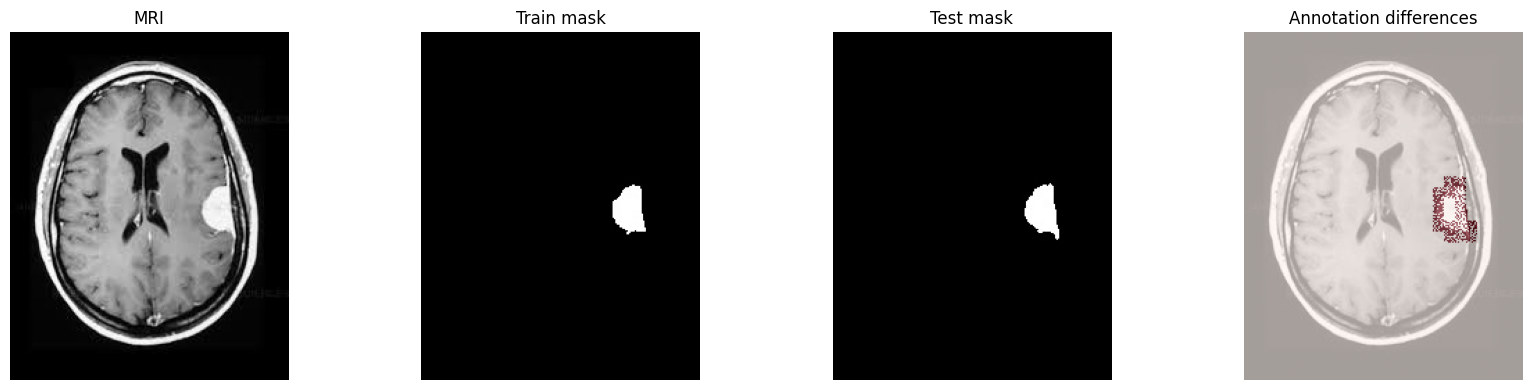

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Select the duplicated MRI group with the largest mask difference
target_hash = mask_pixel_comparison.sort_values(
    "max_difference_ratio",
    ascending=False
).iloc[0]["image_hash"]

group = comparison_df[
    comparison_df["sha256"].str.startswith(target_hash)
].sort_values("split")

row_train = group[group["split"] == "train"].iloc[0]
row_test = group[group["split"] == "test"].iloc[0]

image = np.array(Image.open(row_train["path"]).convert("L"))

mask_train = np.array(
    Image.open(row_train["mask_path"]).convert("L")
)

mask_test = np.array(
    Image.open(row_test["mask_path"]).convert("L")
)

difference = mask_train != mask_test

fig, axes = plt.subplots(1, 4, figsize=(17, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("MRI")

axes[1].imshow(mask_train, cmap="gray")
axes[1].set_title("Train mask")

axes[2].imshow(mask_test, cmap="gray")
axes[2].set_title("Test mask")

axes[3].imshow(image, cmap="gray")
axes[3].imshow(difference, cmap="Reds", alpha=0.65)
axes[3].set_title("Annotation differences")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Exact duplicate audit — Findings and split strategy

The integrity audit confirmed that all 4,793 segmentation images have an associated mask, with no missing files or unmatched image–mask pairs.

However, exact duplicate analysis identified:

- **4,753 unique image SHA256 hashes** among 4,793 images.
- **76 images** belonging to 36 exact-duplicate groups.
- **7 image hashes crossing the official train/test split**, involving 16 image files.
- No conflicting pathology labels or anatomical plane labels within these cross-split duplicate groups.

For all seven cross-split duplicate groups, the associated mask files had different SHA256 hashes and were not pixel-identical. Pixel-level differences ranged from approximately 0.30% to 1.12% of the image area. Visual inspection of one representative case showed broadly similar tumor locations and shapes, with differences in the annotations.

**Methodological decision**

The official BRISC train/test partitions will be retained as the starting point. However, test images whose exact image SHA256 hash is already present in the training set will be excluded from the final evaluation, together with their corresponding masks.

The original dataset will remain unchanged, and the filtering procedure will be documented and applied reproducibly.


In [19]:
import numpy as np
import pandas as pd
from PIL import Image

mask_stats = []

for _, row in seg_masks.iterrows():

    mask = np.array(
        Image.open(row["path"]).convert("L")
    )

    unique_values = np.unique(mask)

    # Provisional binary interpretation:
    # every non-zero pixel is considered part of the tumor
    binary_mask = mask > 0

    tumor_pixels = int(binary_mask.sum())
    total_pixels = binary_mask.size

    mask_stats.append({
        "filename": row["filename"],
        "split": row["split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "width": mask.shape[1],
        "height": mask.shape[0],
        "n_unique_values": len(unique_values),
        "min_value": int(mask.min()),
        "max_value": int(mask.max()),
        "tumor_pixels": tumor_pixels,
        "tumor_ratio": tumor_pixels / total_pixels
    })

mask_stats = pd.DataFrame(mask_stats)

print("Masks analyzed:", len(mask_stats))

print("\nUnique-value counts:")
display(mask_stats["n_unique_values"].value_counts().sort_index())

print("\nEmpty masks:", (mask_stats["tumor_pixels"] == 0).sum())

print("\nTumor area distribution:")
display(
    mask_stats["tumor_ratio"].describe(
        percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
    )
)

print("\nTumor area by pathology:")
display(
    mask_stats.groupby("tumor_label")["tumor_ratio"]
              .describe()
)

Masks analyzed: 4793

Unique-value counts:


,count
n_unique_values,
10,2
11,12
12,101
13,397
14,1043
15,1710
16,1436
17,89
18,3



Empty masks: 0

Tumor area distribution:


,tumor_ratio
count,4793.000000
mean,0.018851
std,0.015946
min,0.000412
5%,0.003735
25%,0.008396
50%,0.014286
75%,0.023640
95%,0.049825
max,0.196094



Tumor area by pathology:


,count,mean,std,min,25%,50%,75%,max
tumor_label,,,,,,,,
glioma,1401.0,0.020561,0.015510,0.000824,0.009487,0.017090,0.026798,0.106716
meningioma,1635.0,0.024784,0.019633,0.000412,0.011568,0.019356,0.032528,0.196094
pituitary,1757.0,0.011966,0.007806,0.000938,0.006538,0.010136,0.015396,0.069042


In [20]:
from collections import Counter
import numpy as np
from PIL import Image

pixel_value_counts = Counter()

for path in seg_masks["path"]:
    mask = np.array(Image.open(path).convert("L"))

    values, counts = np.unique(mask, return_counts=True)
    pixel_value_counts.update(
        dict(zip(values.tolist(), counts.tolist()))
    )

pixel_value_counts = dict(sorted(pixel_value_counts.items()))

print("Distinct pixel values:", list(pixel_value_counts.keys()))
print("\nPixel frequencies:")

display(
    pd.DataFrame({
        "pixel_value": list(pixel_value_counts.keys()),
        "count": list(pixel_value_counts.values())
    })
)

Distinct pixel values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255]

Pixel frequencies:


,pixel_value,count
0,0,1200811122
1,1,1056504
2,2,631720
3,3,316052
4,4,116433
5,5,49648
6,6,10036
7,7,5197
8,8,118
9,9,7


In [21]:
# Final binary threshold based on observed mask values
MASK_THRESHOLD = 128

corrected_stats = []

for _, row in seg_masks.iterrows():

    mask = np.array(
        Image.open(row["path"]).convert("L")
    )

    binary_mask = mask >= MASK_THRESHOLD

    corrected_stats.append({
        "filename": row["filename"],
        "tumor_pixels_corrected": int(binary_mask.sum()),
        "tumor_ratio_corrected": float(binary_mask.mean())
    })

corrected_stats = pd.DataFrame(corrected_stats)

mask_stats = mask_stats.merge(
    corrected_stats,
    on="filename",
    how="left",
    validate="one_to_one"
)

print("Empty masks after thresholding:",
      (mask_stats["tumor_pixels_corrected"] == 0).sum())

print("\nCorrected tumor area distribution:")
display(
    mask_stats["tumor_ratio_corrected"].describe(
        percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
    )
)

print("\nCorrected tumor area by pathology:")
display(
    mask_stats.groupby("tumor_label")["tumor_ratio_corrected"]
              .describe()
)

print("\nDifference from provisional threshold:")
print(
    "Mean area ratio before:",
    mask_stats["tumor_ratio"].mean()
)
print(
    "Mean area ratio after:",
    mask_stats["tumor_ratio_corrected"].mean()
)

Empty masks after thresholding: 0

Corrected tumor area distribution:


,tumor_ratio_corrected
count,4793.000000
mean,0.016937
std,0.014973
min,0.000088
5%,0.002905
25%,0.007099
50%,0.012554
75%,0.021439
95%,0.046210
max,0.173472



Corrected tumor area by pathology:


,count,mean,std,min,25%,50%,75%,max
tumor_label,,,,,,,,
glioma,1401.0,0.018668,0.014809,0.000534,0.008163,0.015205,0.024559,0.097702
meningioma,1635.0,0.022454,0.018282,0.000088,0.009954,0.017363,0.029757,0.173472
pituitary,1757.0,0.010423,0.007266,0.000584,0.005436,0.008636,0.013538,0.064871



Difference from provisional threshold:
Mean area ratio before: 0.01885059393875821
Mean area ratio after: 0.016936790549588864


### Mask integrity and tumor-area analysis

All 4,793 segmentation masks were successfully loaded, and none was empty.

The original grayscale masks contained between 10 and 18 distinct pixel values, with observed intensities restricted to two separate ranges: 0–10 and 246–255. This pattern is consistent with predominantly binary annotations containing small intensity variations.

Based on this distribution, a threshold of **128** was selected to convert the masks into binary labels (0 = background, 1 = tumor).

After binarization:

- Mean tumor area ratio: **1.69%**
- Median tumor area ratio: **1.26%**
- 95th percentile: **4.62%**
- Empty masks: **0**

The average estimated tumor area decreased from 1.89% under the provisional nonzero-pixel threshold to 1.69% after binarization.

Tumor-area distributions also differed across pathologies. Median annotated area was approximately 1.74% for meningioma, 1.52% for glioma, and 0.86% for pituitary tumors.

These measurements represent the proportion of annotated pixels in individual 2D MRI images, not physical tumor area or 3D tumor volume.

**Implications for model development**

The dataset exhibits substantial pixel-level class imbalance, with tumor pixels accounting for only a small fraction of each image. Consequently, pixel accuracy alone would be an inadequate measure of segmentation performance.

Dice coefficient and Intersection over Union (IoU) will be prioritized for evaluation, with performance additionally examined by pathology, anatomical plane, and lesion size.

The binary threshold of 128 will be applied consistently during training and evaluation.

In [23]:
# Select representative samples

import pandas as pd

# 1. Prepare mask metadata and statistics
mask_lookup = seg_masks.copy()

mask_lookup["image_key"] = (
    mask_lookup["linked_image"]
    .str.replace("\\", "/", regex=False)
)

mask_lookup = mask_lookup.merge(
    mask_stats[["filename", "tumor_ratio_corrected"]],
    on="filename",
    how="left",
    validate="one_to_one"
)

# 2. Prepare image metadata
visual_df = seg_images.copy()

visual_df["image_key"] = (
    visual_df["relative_path"]
    .str.replace("\\", "/", regex=False)
)

# 3. Link each image to its mask and tumor statistics
visual_df = visual_df.merge(
    mask_lookup[
        ["image_key", "path", "tumor_ratio_corrected"]
    ].rename(columns={"path": "mask_path"}),
    on="image_key",
    how="left",
    validate="one_to_one"
)

# 4. Verify integrity
assert visual_df["mask_path"].notna().all()
assert visual_df["tumor_ratio_corrected"].notna().all()

print("Images with valid masks and statistics:", len(visual_df))

# 5. Select samples from training partition
train_visual = visual_df[
    visual_df["split"] == "train"
].copy()

selected_rows = []

quantiles = {
    "Small": 0.05,
    "Medium": 0.50,
    "Large": 0.95
}

for pathology, group in train_visual.groupby("tumor_label"):

    used_indices = set()

    for size_label, q in quantiles.items():

        target = group["tumor_ratio_corrected"].quantile(q)

        candidates = group.loc[
            ~group.index.isin(used_indices)
        ]

        idx = (
            candidates["tumor_ratio_corrected"]
            .sub(target)
            .abs()
            .idxmin()
        )

        used_indices.add(idx)

        row = group.loc[idx].copy()
        row["size_category"] = size_label

        selected_rows.append(row)

visual_samples = pd.DataFrame(selected_rows)

display(
    visual_samples[
        [
            "tumor_label",
            "size_category",
            "plane_label",
            "tumor_ratio_corrected"
        ]
    ]
)

Images with valid masks and statistics: 4793


,tumor_label,size_category,plane_label,tumor_ratio_corrected
1608,glioma,Small,coronal,0.002892
1824,glioma,Medium,sagittal,0.015560
1790,glioma,Large,sagittal,0.047295
2701,meningioma,Small,coronal,0.003731
2583,meningioma,Medium,coronal,0.016705
2862,meningioma,Large,sagittal,0.050415
3418,pituitary,Small,axial,0.002571
3634,pituitary,Medium,axial,0.009037
3439,pituitary,Large,axial,0.023247


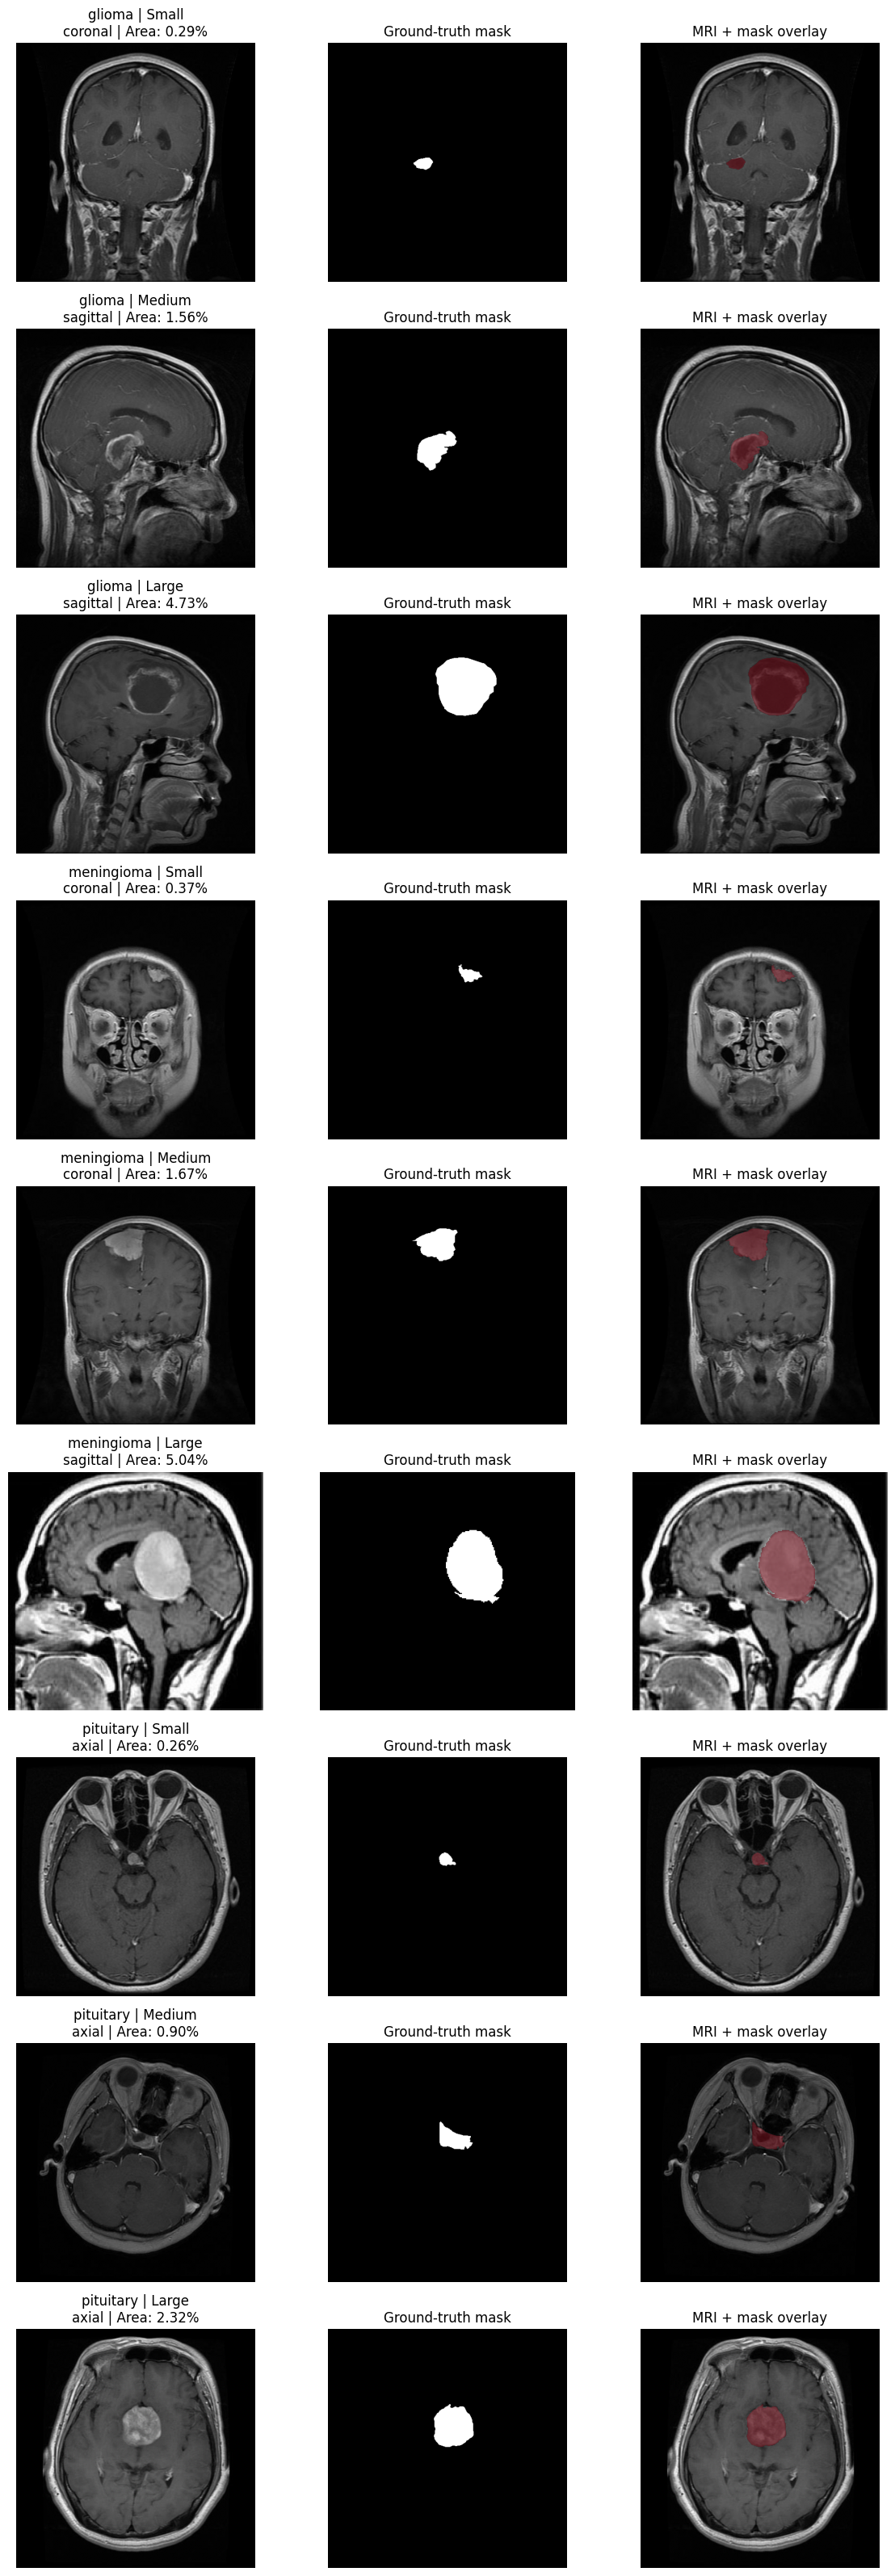

In [24]:
# Visualize MRI, binary mask and overlay

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(
    nrows=len(visual_samples),
    ncols=3,
    figsize=(12, 32)
)

for i, (_, row) in enumerate(visual_samples.iterrows()):

    image = np.array(
        Image.open(row["path"]).convert("L")
    )

    mask = np.array(
        Image.open(row["mask_path"]).convert("L")
    )

    binary_mask = mask >= MASK_THRESHOLD

    # Original MRI
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(
        f"{row['tumor_label']} | {row['size_category']}\n"
        f"{row['plane_label']} | "
        f"Area: {row['tumor_ratio_corrected']:.2%}"
    )

    # Binary mask
    axes[i, 1].imshow(
        binary_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 1].set_title("Ground-truth mask")

    # MRI + transparent tumor overlay
    axes[i, 2].imshow(image, cmap="gray")

    overlay = np.ma.masked_where(
        ~binary_mask,
        binary_mask.astype(float)
    )

    axes[i, 2].imshow(
        overlay,
        cmap="Reds",
        vmin=0,
        vmax=1,
        alpha=0.55
    )

    axes[i, 2].set_title("MRI + mask overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Visual inspection of MRI–mask pairs

Nine representative training samples were visually inspected, covering three tumor pathologies (glioma, meningioma, and pituitary) and three relative lesion-size categories (small, medium, and large).

For each sample, the original MRI image, binarized ground-truth mask, and MRI–mask overlay were displayed.

**Key observations**

- All nine inspected masks were spatially aligned with their corresponding MRI images, with no obvious image–mask misalignment.
- Annotated regions varied substantially in size, shape, and anatomical location.
- Small lesions remained visible after binarization using the threshold of 128.
- Some lesions exhibited heterogeneous internal MRI intensities, confirming that segmentation cannot be reduced to simple image-intensity thresholding.
- The selected examples included axial, coronal, and sagittal images, although anatomical planes were not equally represented within each pathology.

**Conclusion**

The visual inspection did not reveal obvious pairing or spatial alignment issues in the selected examples.

Combined with the preceding integrity checks and mask-value analysis, these findings support proceeding with a supervised segmentation baseline.